# SPIRES fSCA and categorical snow change
Crop SPIRES fSCA to the NISAR AOI, classify snow cover, and compute categorical snow change for each NISAR pair on the native SPIRES grid, an 80 m grid and a 20 m grid.

In [38]:
import numpy as np
import pandas as pd
import xarray as xr
import rioxarray  # noqa: F401
import matplotlib.pyplot as plt
from matplotlib.colors import ListedColormap, BoundaryNorm
from rasterio.enums import Resampling
from pathlib import Path
from seaborn import set_theme
set_theme()

import sys
import os

# import from this repo
project_root = str(Path(os.getcwd()).parent)
if project_root not in sys.path:
    sys.path.append(project_root)

%load_ext autoreload
%autoreload 2
from scripts.fsca import build_fsca_cube, classify_fsca, classify_change

The autoreload extension is already loaded. To reload it, use:
  %reload_ext autoreload


First, we setup logging to get useful information and error messages.

In [39]:
import logging
logging.basicConfig(level=logging.INFO, format='%(asctime)s - %(levelname)s - %(message)s', force=True)

Load the NISAR cubes and list the SPIRES files (the MODIS tile covering the AOI).

In [ ]:
data_dir = "../data/"
track = 19
frame = 21
tile = "h09v05"
nisar_dir = data_dir + f'nisar/zarrs/track{str(track).zfill(3)}_frame{str(frame).zfill(3)}/'

nisar_80m = xr.open_zarr(nisar_dir + 'snow_80m.zarr')
nisar_20m = xr.open_zarr(nisar_dir + 'snow_20m.zarr')

starts = nisar_80m['start'].values
ends = nisar_80m['end'].values
pairs = nisar_80m['pair'].values

dates = pd.DatetimeIndex(np.concatenate([starts, ends])).normalize().unique().sort_values()
fsca_files = sorted(Path(data_dir + f'fsca_spires/{tile}').glob('SPIRES_HIST_*.nc'))
len(fsca_files)

365

Plotting helpers shared by all three sections: fSCA by date, snow class by date and snow change by pair, with labeled categorical colorbars.

In [53]:
cat_cmap = ListedColormap(['#d9d9d9', '#9ecae1', '#08519c'])
change_cmap = ListedColormap(['#d9d9d9', '#9ecae1', '#08519c', '#a1d99b', '#238b45', '#fdae6b', '#d94801'])

def plot_panels(da, items, sel_dim, titles, ncols, label=None, tick_labels=None, **kwargs):
    """Grid of maps of `da` for each item along `sel_dim` with one shared colorbar (labeled ticks if categorical)."""
    nrows = int(np.ceil(len(items) / ncols))
    fig, axes = plt.subplots(nrows, ncols, figsize=(3.2 * ncols, 2.8 * nrows), sharex=True, sharey=True)
    for ax, item, title in zip(axes.ravel(), items, titles):
        im = da.sel({sel_dim: item}).plot.imshow(ax=ax, add_colorbar=False, **kwargs)
        ax.set_title(title)
        ax.grid(False)
        ax.set_xlabel('')
        ax.set_ylabel('')
    for ax in axes.ravel()[len(items):]:
        ax.set_visible(False)
    cb = fig.colorbar(im, ax=axes, label=label, ticks=None if tick_labels is None else list(tick_labels))
    if tick_labels is not None:
        cb.set_ticklabels([f'{i}: {l}' for i, l in tick_labels.items()])
    fig.supxlabel('x (m)')
    fig.supylabel('y (m)')
    plt.show()


def plot_fsca(fsca):
    plot_panels(fsca, dates, 'time', [str(t.date()) for t in dates], 5, label='fSCA (%)', cmap='Blues', vmin=0, vmax=100)


def plot_cat(snow_class):
    labels = dict(enumerate(snow_class.attrs['class_labels']))
    norm = BoundaryNorm(np.arange(-0.5, len(labels)), cat_cmap.N)
    plot_panels(snow_class.where(snow_class >= 0), dates, 'time', [str(t.date()) for t in dates], 5, tick_labels=labels, cmap=cat_cmap, norm=norm)


def plot_change(snow_change):
    labels = snow_change.attrs['change_labels']
    norm = BoundaryNorm(np.arange(-0.5, len(labels)), change_cmap.N)
    plot_panels(snow_change.where(snow_change >= 0), pairs, 'pair', pairs, 5, tick_labels=labels, cmap=change_cmap, norm=norm)

# Native SPIRES grid (~463 m)
Build the fSCA cube over the NISAR bounding box, in the NISAR UTM zone. Pass a different `(xmin, ymin, xmax, ymax)` in that CRS to use another AOI.

In [ ]:
aoi = nisar_80m.rio.bounds()
fsca = build_fsca_cube(fsca_files, aoi, nisar_80m.rio.crs)
fsca

2026-10-14 20:55:20,311 - INFO - fsca cube: {'time': 365, 'y': 61, 'x': 47} from 2025-10-01T00:00:00.000000000 to 2026-09-30T00:00:00.000000000


<xarray.DataArray 'fsca' (time: 365, y: 61, x: 47)> Size: 4MB
array([[[0., 0., 0., ..., 0., 0., 0.],
        [0., 0., 0., ..., 0., 0., 0.],
        [0., 0., 0., ..., 0., 0., 0.],
        ...,
        [0., 0., 0., ..., 0., 0., 0.],
        [0., 0., 0., ..., 0., 0., 0.],
        [0., 0., 0., ..., 0., 0., 0.]],

       [[0., 0., 0., ..., 0., 0., 0.],
        [0., 0., 0., ..., 0., 0., 0.],
        [0., 0., 0., ..., 0., 0., 0.],
        ...,
        [0., 0., 0., ..., 0., 0., 0.],
        [0., 0., 0., ..., 0., 0., 0.],
        [0., 0., 0., ..., 0., 0., 0.]],

       [[0., 0., 0., ..., 0., 0., 0.],
        [0., 0., 0., ..., 0., 0., 0.],
        [0., 0., 0., ..., 0., 0., 0.],
        ...,
...
        [0., 0., 0., ..., 0., 0., 0.],
        [0., 0., 0., ..., 0., 0., 0.],
        [0., 0., 0., ..., 0., 0., 0.]],

       [[0., 0., 0., ..., 0., 0., 0.],
        [0., 0., 0., ..., 0., 0., 0.],
        [0., 0., 0., ..., 0., 0., 0.],
        ...,
        [0., 0., 0., ..., 0., 0., 0.],
        [0., 0., 0., ..., 0., 0., 0.],
        [0., 0., 0., ..., 0., 0., 0.]],

       [[0., 0., 0., ..., 0., 0., 0.],
        [0., 0., 0., ..., 0., 0., 0.],
        [0., 0., 0., ..., 0., 0., 0.],
        ...,
        [0., 0., 0., ..., 0., 0., 0.],
        [0., 0., 0., ..., 0., 0., 0.],
        [0., 0., 0., ..., 0., 0., 0.]]],
      shape=(365, 61, 47), dtype=float32)
Coordinates:
  * time         (time) datetime64[ns] 3kB 2025-10-01 2025-10-02 ... 2026-09-30
  * y            (y) float64 488B 4.323e+06 4.322e+06 ... 4.281e+06 4.281e+06
  * x            (x) float64 376B 3.162e+05 3.169e+05 ... 3.477e+05 3.484e+05
    spatial_ref  int64 8B 0
Attributes:
    long_name:  fractional snow covered area
    units:      %

fSCA on each pair start and end date.

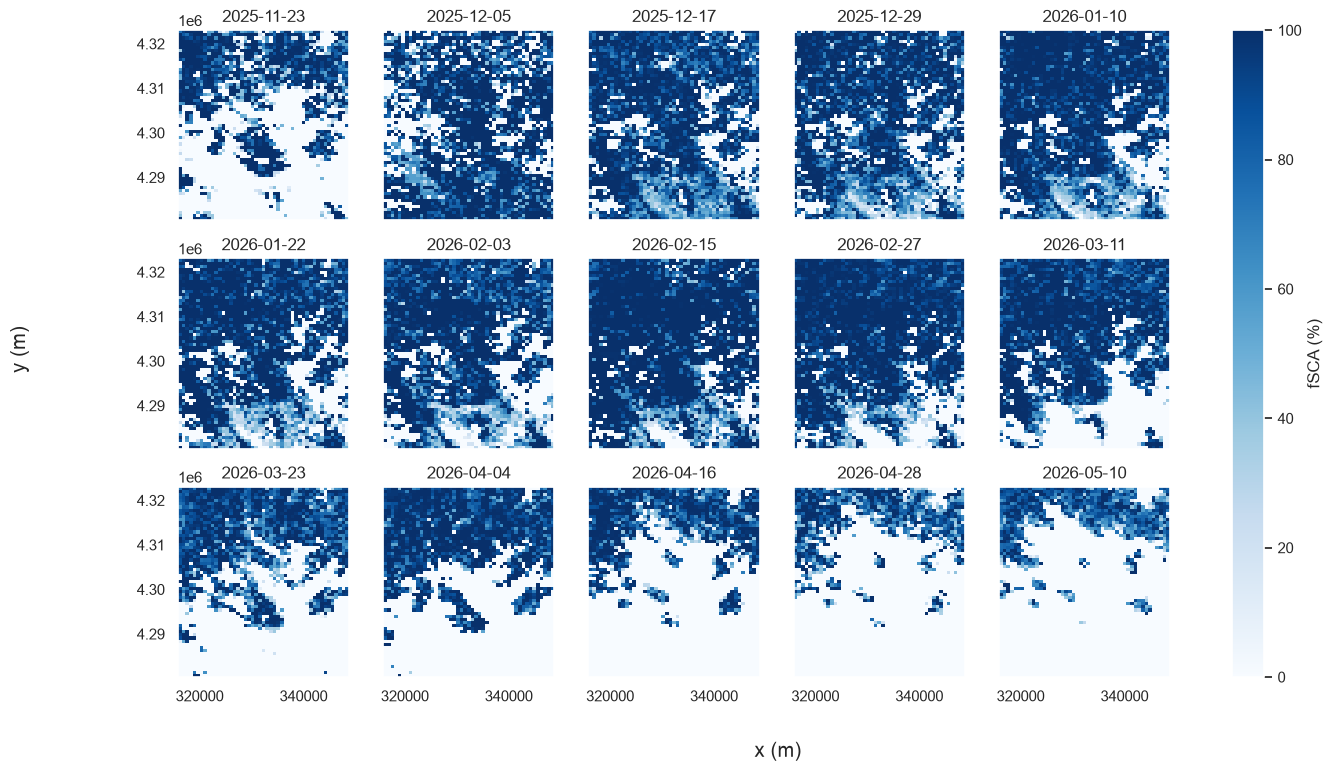

In [55]:
plot_fsca(fsca.sel(time=dates))

Classify fSCA into snow cover categories. Default: 0 = no snow (<20%), 1 = patchy (20-70%), 2 = snow (≥70%); pass `bins` and `labels` to `classify_fsca` to change.

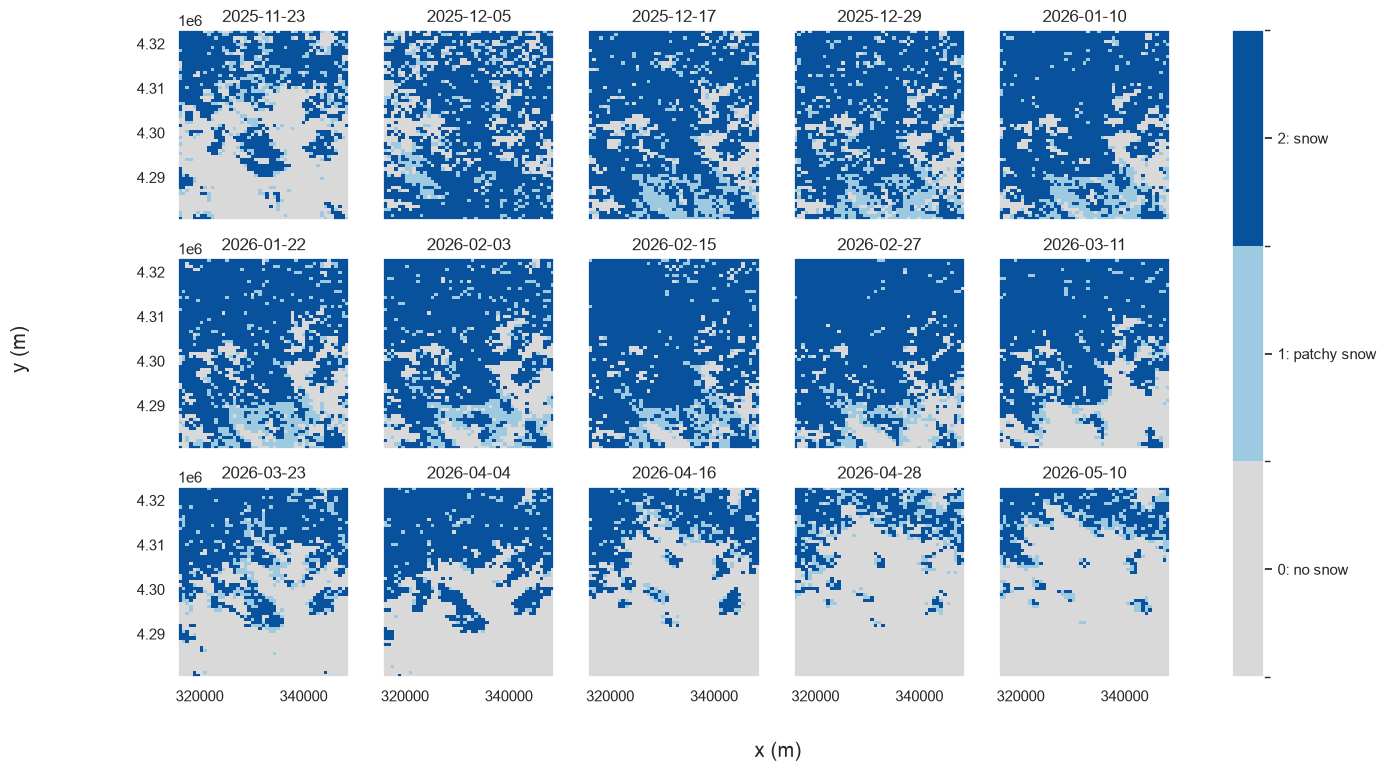

In [56]:
snow_class = classify_fsca(fsca)
plot_cat(snow_class)

Categorical change for each NISAR pair. Stable classes keep their code (0 = no snow both days); increases and decreases are coded by how many classes changed.

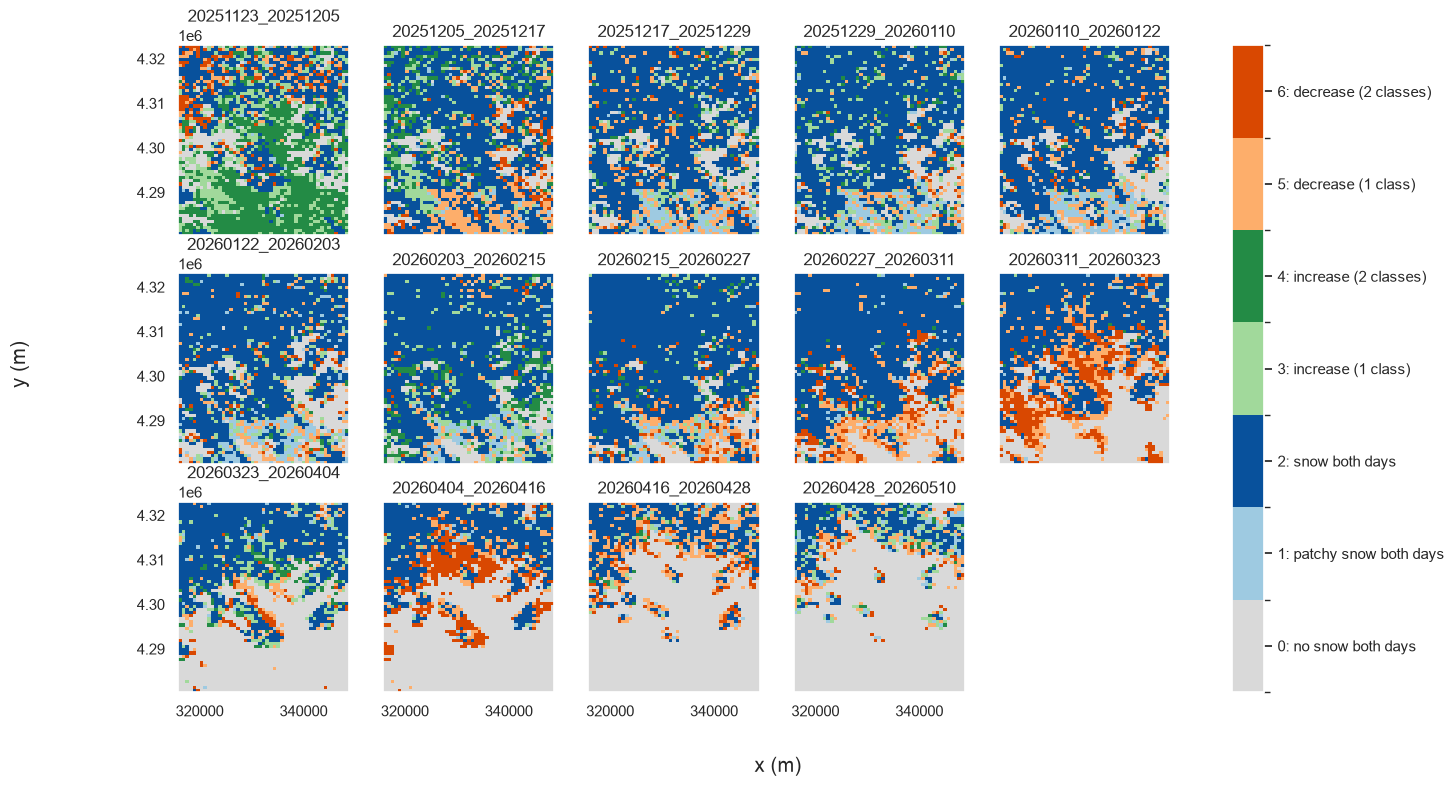

In [57]:
snow_change = classify_change(snow_class, starts, ends, pair=pairs)
plot_change(snow_change)

# 80 m grid
Bilinearly interpolate fSCA to the 80 m NISAR grid (masked to the pixels with valid elevation), then classify and compute change.

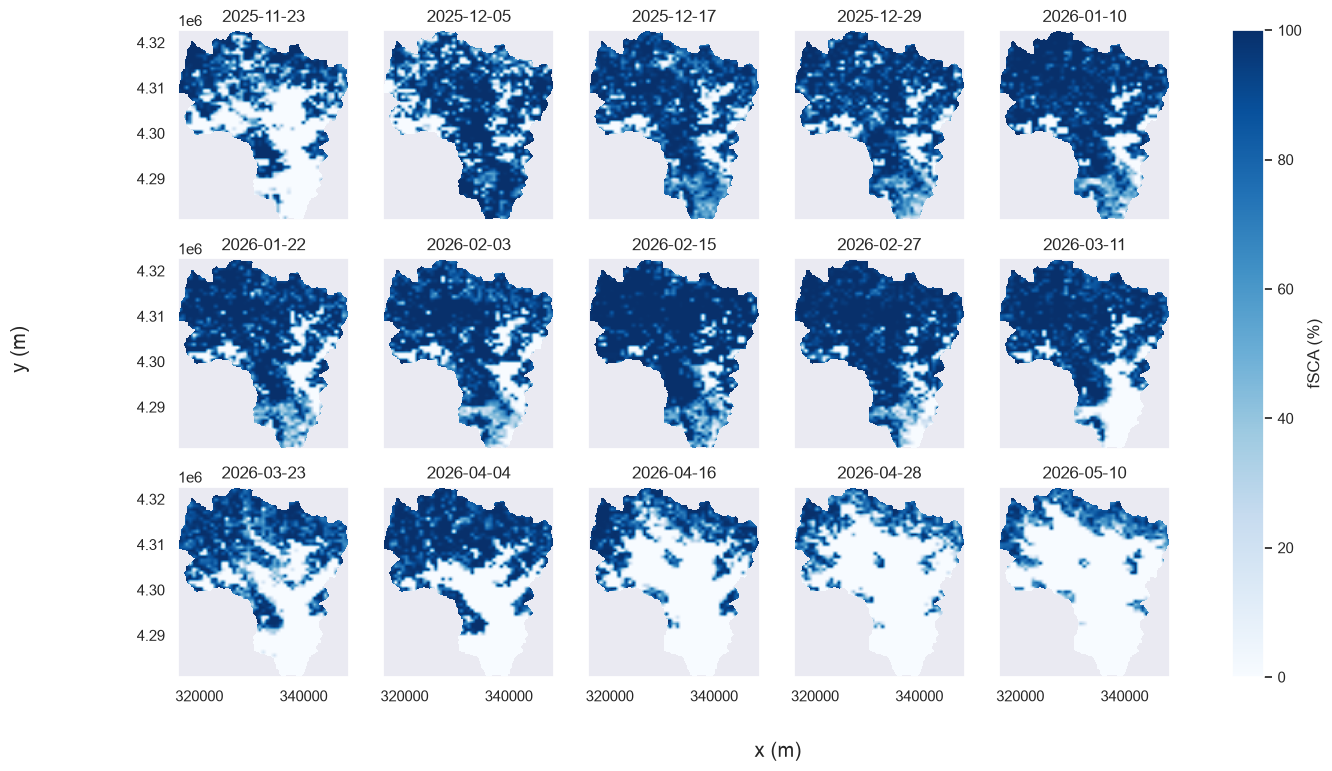

In [58]:
elev_80m = nisar_80m['elevation'].load()
fsca_80m = fsca.rio.reproject_match(elev_80m, resampling=Resampling.bilinear).where(elev_80m.notnull())
plot_fsca(fsca_80m.sel(time=dates))

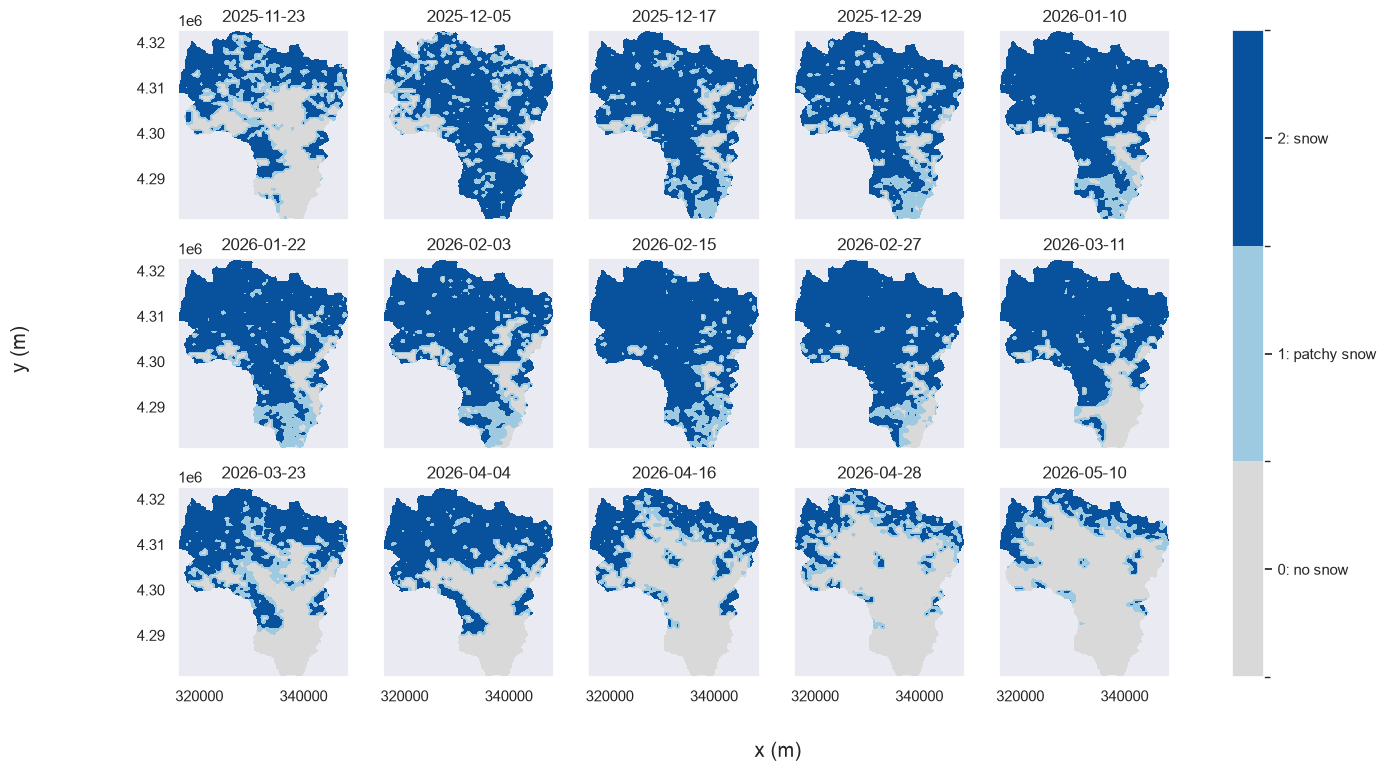

In [59]:
snow_class_80m = classify_fsca(fsca_80m)
plot_cat(snow_class_80m)

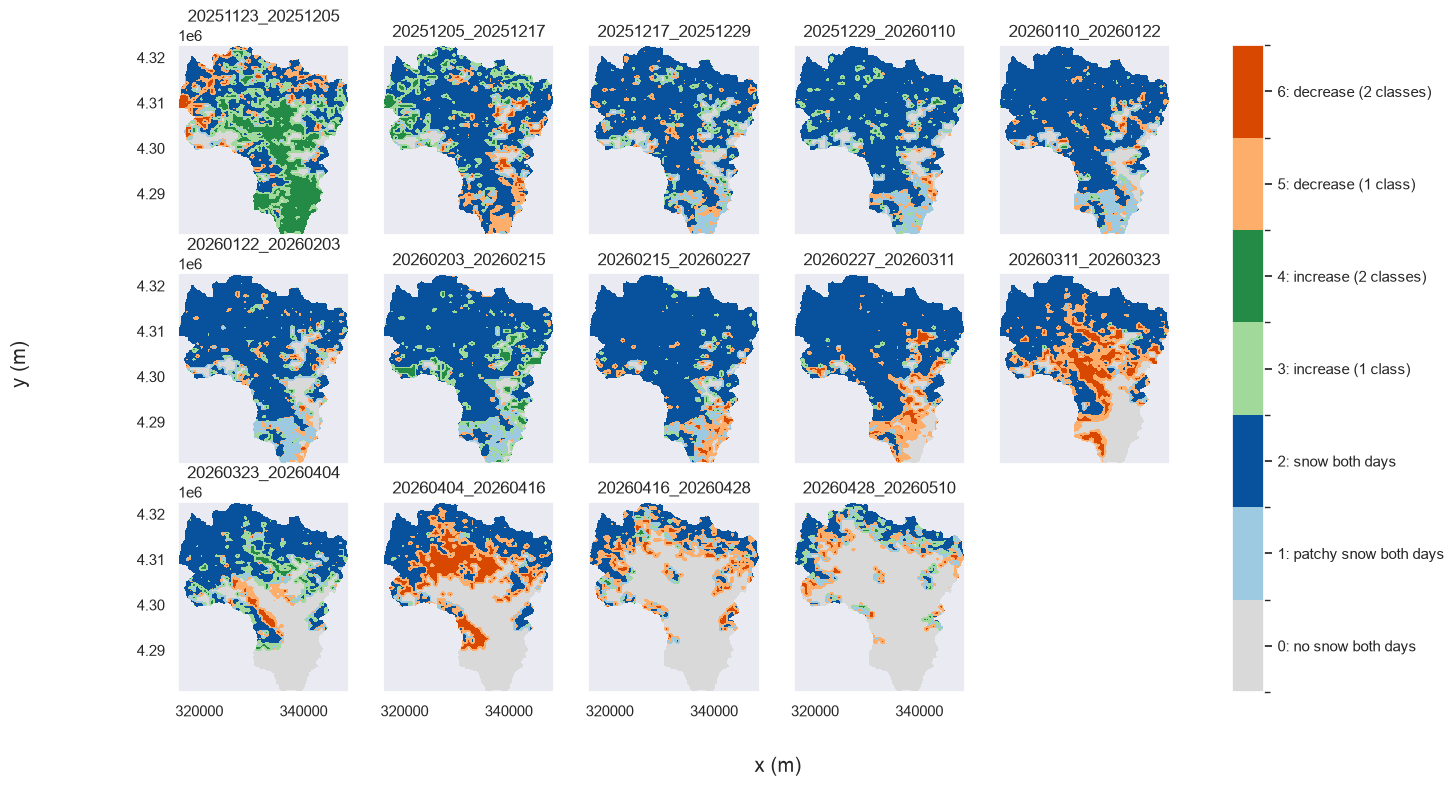

In [60]:
snow_change_80m = classify_change(snow_class_80m, starts, ends, pair=pairs)
plot_change(snow_change_80m)

# 20 m grid
Same, using the 20 m grid in `nisar_20m`.

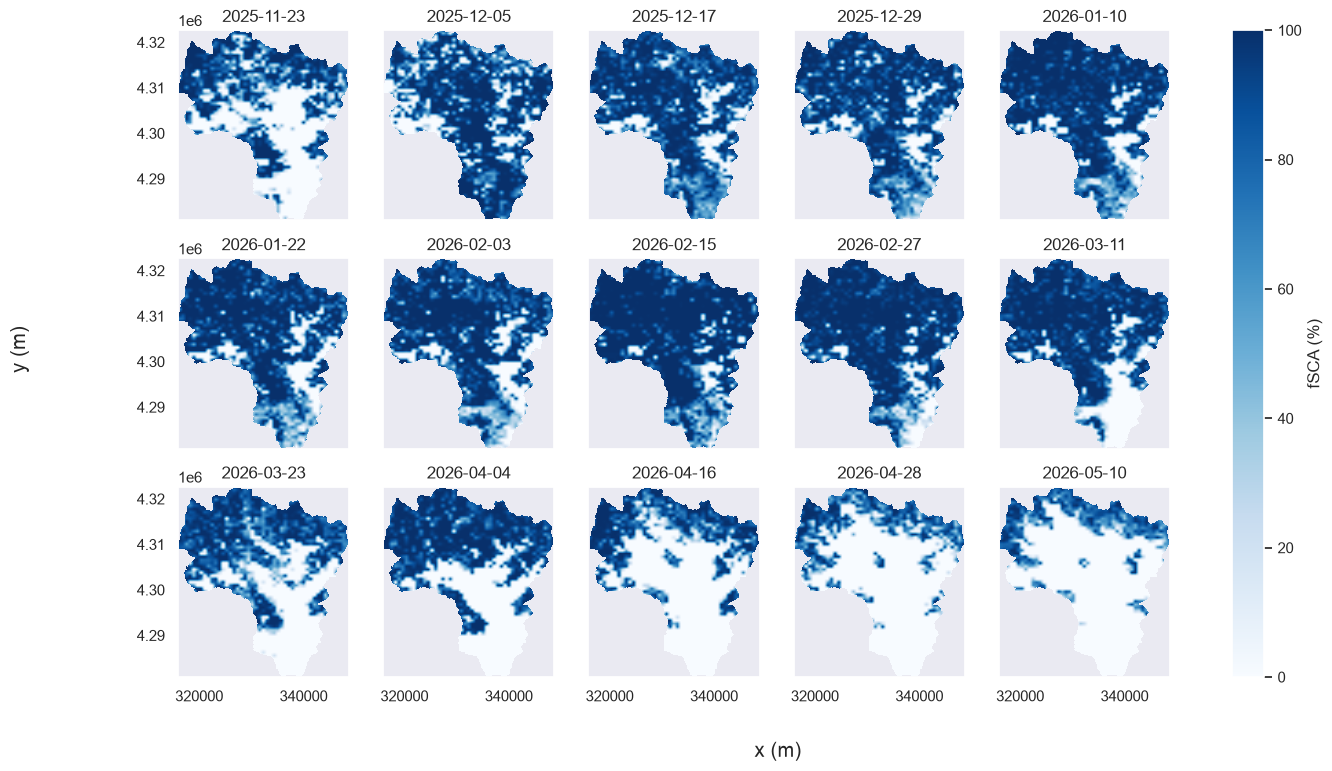

In [61]:
elev_20m = nisar_20m['elevation'].load()
fsca_20m = fsca.rio.reproject_match(elev_20m, resampling=Resampling.bilinear).where(elev_20m.notnull())
plot_fsca(fsca_20m.sel(time=dates))

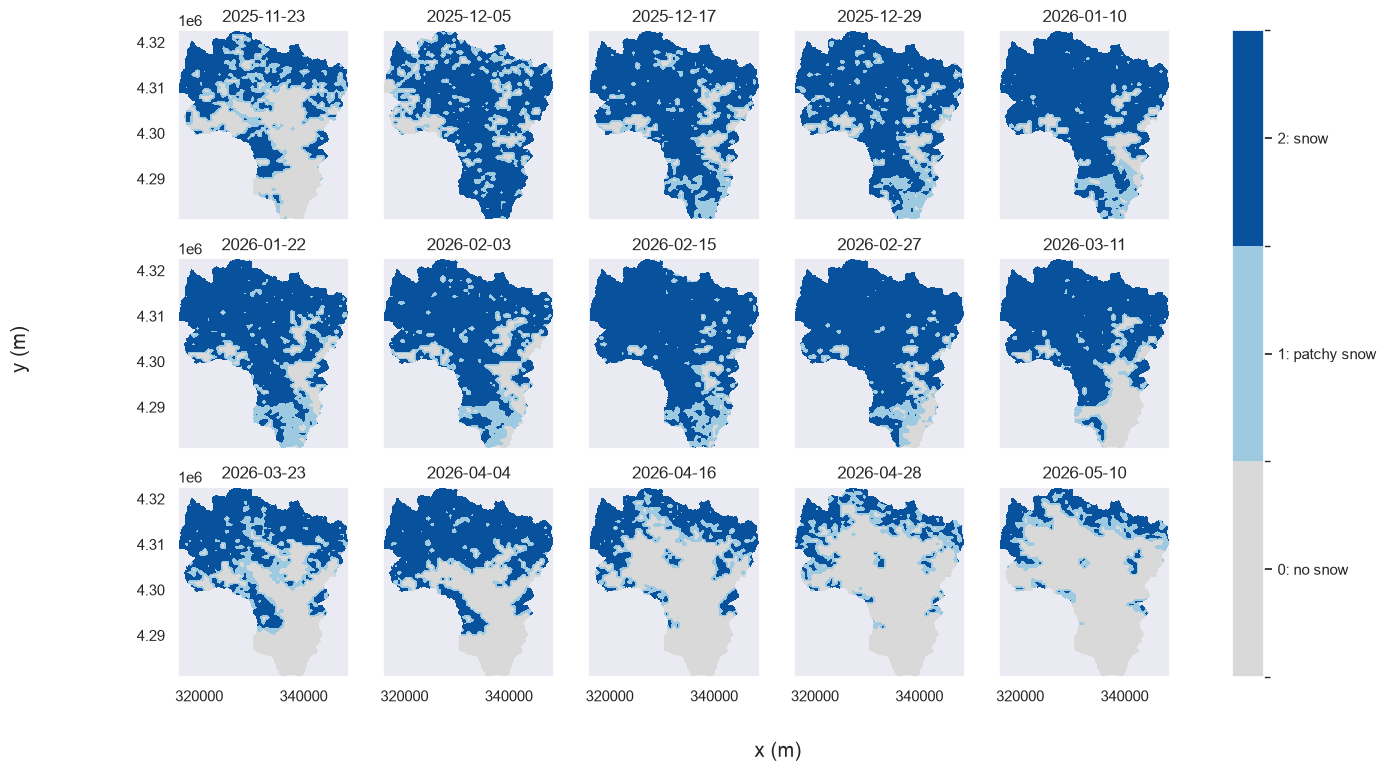

In [62]:
snow_class_20m = classify_fsca(fsca_20m)
plot_cat(snow_class_20m)

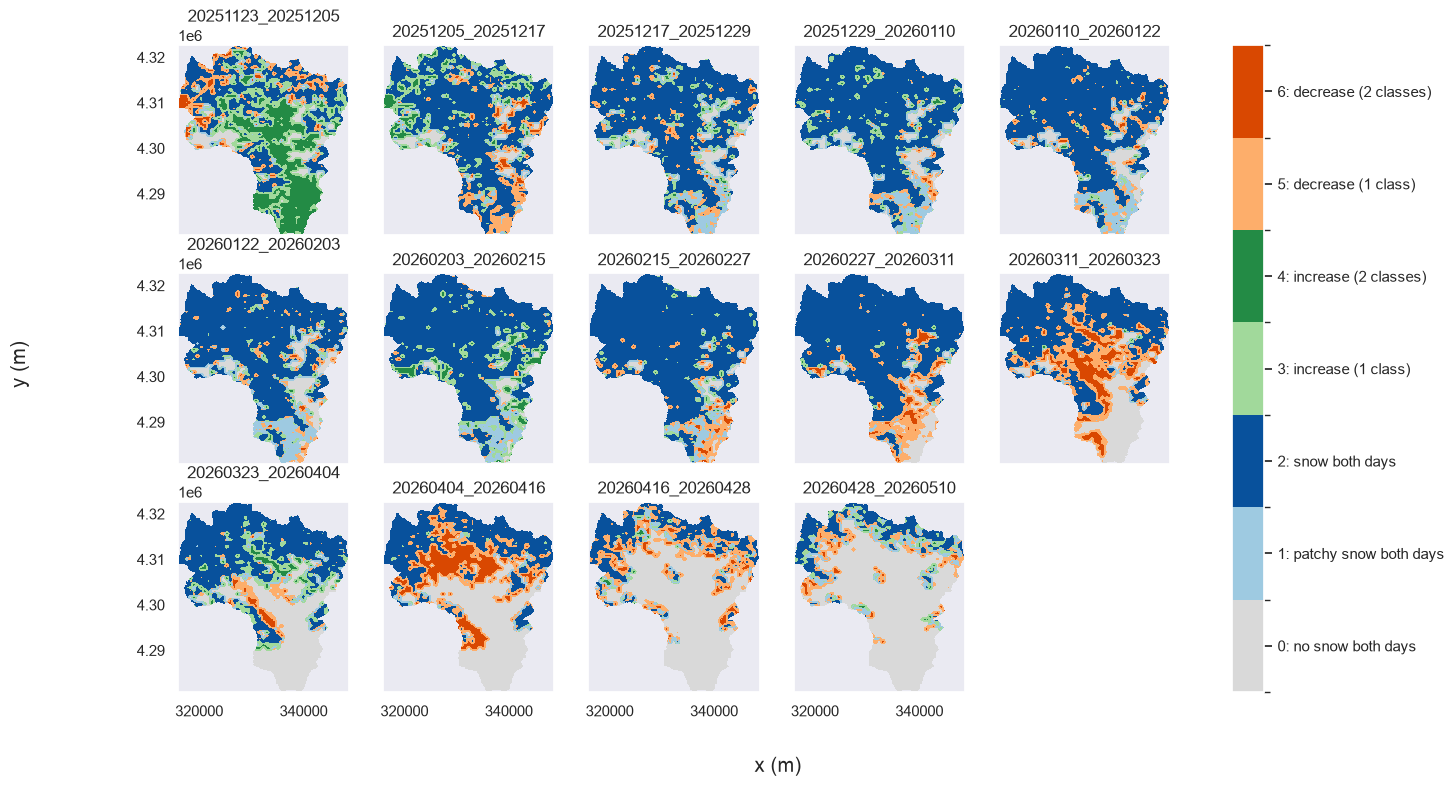

In [63]:
snow_change_20m = classify_change(snow_class_20m, starts, ends, pair=pairs)
plot_change(snow_change_20m)

In [64]:
fsca_20m.to_zarr(data_dir + f'fsca_spires/zarrs/erb_fsca_20m.zarr', mode="w", align_chunks=True)
fsca_80m.to_zarr(data_dir + f'fsca_spires/zarrs/erb_fsca_80m.zarr', mode="w", align_chunks=True)

/Users/JULIALOBER/miniforge3/envs/coherence/lib/python3.11/site-packages/zarr/api/asynchronous.py:247: ZarrUserWarning: Consolidated metadata is currently not part in the Zarr format 3 specification. It may not be supported by other zarr implementations and may change in the future.
  warnings.warn(
/Users/JULIALOBER/miniforge3/envs/coherence/lib/python3.11/site-packages/zarr/api/asynchronous.py:247: ZarrUserWarning: Consolidated metadata is currently not part in the Zarr format 3 specification. It may not be supported by other zarr implementations and may change in the future.
  warnings.warn(
